# Импорт и основные настройки

In [2]:
%pip install ultralytics optuna mlflow pyyaml pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 40.7 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 56.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 60.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 67.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 47.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 57.5 MB/s  0:00:00m0:00:0100:01
  Attempting uninstall: protobuf━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  6/41 [pyarrow]
    Found existing installation: protobuf 7.35.1━━━━━━━━━━━━━━  6/41 [pyarrow]
    Uninstalling protobuf-7.35.1:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  7/41 [protobuf]
      Successfully uninstalled protobuf-7.35.1━━━━━━━━━━━━━━━━  7/41 [protobuf]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41/41 [mlflow] [mlflow] [mlflow-skinny]]dk]onventions]
Note: you may need to restart the kernel to use updated packages.


In [5]:
from pathlib import Path
import json

import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
import ultralytics

import optuna
import mlflow


# Путь к корневой папке датасета
DATASET_DIR = Path(
    r"/home/dataset"
)

# data.yaml
DATA_YAML = DATASET_DIR / "data.yaml"

# YOLO26
MODEL_WEIGHTS = "yolo26m.pt"

# Максимум эпох на ОДИН Optuna trial
MAX_EPOCHS = 50

# Максимальное количество trial
N_TRIALS = 5

# GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"


# ============================================================
# ПАПКИ ПРОЕКТА
# ============================================================

PROJECT_DIR = Path.cwd()

RUNS_DIR = PROJECT_DIR / "runs_yolo26"

MLFLOW_DIR = PROJECT_DIR / "mlruns"

OPTUNA_DB = PROJECT_DIR / "optuna_yolo26.db"

# Файл для ручной остановки
STOP_FILE = PROJECT_DIR / "STOP_TRAINING"


# Создаём необходимые папки
RUNS_DIR.mkdir(exist_ok=True)
MLFLOW_DIR.mkdir(exist_ok=True)


# ============================================================
# ИНФОРМАЦИЯ
# ============================================================

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print()
print("Dataset:", DATASET_DIR)
print("data.yaml:", DATA_YAML)
print("Runs:", RUNS_DIR)
print("MLflow:", MLFLOW_DIR)
print("Optuna DB:", OPTUNA_DB)
print("Device:", DEVICE)

Ultralytics: 8.4.164
PyTorch: 2.13.0+cu130
CUDA: True
GPU: NVIDIA GeForce RTX 4090

Dataset: /home/dataset
data.yaml: /home/dataset/data.yaml
Runs: /home/Yolo_26/runs_yolo26
MLflow: /home/Yolo_26/mlruns
Optuna DB: /home/Yolo_26/optuna_yolo26.db
Device: 0


# Проверка датасета

In [6]:
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Папка датасета не найдена:\n{DATASET_DIR}"
    )

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"data.yaml не найден:\n{DATA_YAML}"
    )


with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)


print("=" * 70)
print("DATASET")
print("=" * 70)

print("Количество классов:", data_config.get("nc"))
print("Классы:", data_config.get("names"))

print()
print("train:", data_config.get("train"))
print("val:", data_config.get("val"))
print("test:", data_config.get("test"))

print("=" * 70)

DATASET
Количество классов: 10
Классы: {0: 'Экскаватор', 1: 'Самосвал', 2: 'Грузовой автомобиль', 3: 'Кран', 4: 'Фронтальный погрузчик', 5: 'Автобетоносмеситель', 6: 'Бульдозер', 7: 'Прицеп', 8: 'Каток', 9: 'Автобетононасос'}

train: images/train
val: images/val
test: images/test


# MLflow + Optuna

In [7]:
# ============================================================
# MLFLOW
# ============================================================

MLFLOW_DB = PROJECT_DIR / "mlflow.db"

mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"
)

mlflow.set_experiment(
    "YOLO26_CCTV"
)


# ============================================================
# OPTUNA
# ============================================================

STUDY_NAME = "YOLO26_CCTV_HPO"

storage = (
    f"sqlite:///{OPTUNA_DB.resolve().as_posix()}"
)

study = optuna.create_study(
    study_name=STUDY_NAME,
    storage=storage,
    load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    ),
)


# ============================================================
# INFO
# ============================================================

print("MLflow:", mlflow.get_tracking_uri())
print("MLflow DB:", MLFLOW_DB)

print("Optuna study:", STUDY_NAME)
print("Optuna DB:", OPTUNA_DB)
print("Существующих trial:", len(study.trials))

[I 2026-09-28 19:12:15,982] Using an existing study with `study_name='YOLO26_CCTV_HPO'` instead of creating a new one.


MLflow: sqlite:////home/Yolo_26/mlflow.db
MLflow DB: /home/Yolo_26/mlflow.db
Optuna study: YOLO26_CCTV_HPO
Optuna DB: /home/Yolo_26/optuna_yolo26.db
Существующих trial: 4


# Гиперпараметры + STOP + callbacks

In [8]:
def suggest_cctv_params(trial):

    return {

        "optimizer": trial.suggest_categorical(
            "optimizer",
            ["SGD", "AdamW"]
        ),

        "lr0": trial.suggest_float(
            "lr0",
            1e-4,
            5e-3,
            log=True
        ),

        "lrf": trial.suggest_float(
            "lrf",
            0.01,
            0.2,
            log=True
        ),

        "weight_decay": trial.suggest_float(
            "weight_decay",
            1e-6,
            5e-4,
            log=True
        ),

        "imgsz": trial.suggest_categorical(
            "imgsz",
            [640, 768]
        ),

        "scale": trial.suggest_float(
            "scale",
            0.0,
            0.25
        ),

        "translate": trial.suggest_float(
            "translate",
            0.0,
            0.15
        ),

        "fliplr": trial.suggest_float(
            "fliplr",
            0.0,
            0.5
        ),

        "hsv_h": trial.suggest_float(
            "hsv_h",
            0.0,
            0.02
        ),

        "hsv_s": trial.suggest_float(
            "hsv_s",
            0.0,
            0.5
        ),

        "hsv_v": trial.suggest_float(
            "hsv_v",
            0.0,
            0.5
        ),

        "mosaic": trial.suggest_float(
            "mosaic",
            0.0,
            0.5
        ),
    }



def clear_stop():

    if STOP_FILE.exists():
        STOP_FILE.unlink()


def stop_requested():

    return STOP_FILE.exists()



def make_callbacks(trial, state):

    def on_train_batch_end(trainer):

        # Проверяем STOP после каждого batch
        if stop_requested():

            state["manual_stop"] = True

            print()
            print("=" * 70)
            print("STOP_TRAINING обнаружен")
            print("Остановка после текущего batch...")
            print("=" * 70)

            trainer.stop = True


    def on_fit_epoch_end(trainer):

        epoch = int(trainer.epoch) + 1

        metrics = {}

        # ----------------------------------------------------
        # Получаем метрики
        # ----------------------------------------------------

        if hasattr(trainer, "metrics"):

            for key, value in trainer.metrics.items():

                try:
                    metrics[str(key)] = float(value)
                except:
                    pass


        # ----------------------------------------------------
        # Сохраняем историю
        # ----------------------------------------------------

        state["history"].append({
            "epoch": epoch,
            **metrics
        })

        state["last_epoch"] = epoch


        # ----------------------------------------------------
        # Ищем mAP50-95
        # ----------------------------------------------------

        map5095 = None

        for key, value in metrics.items():

            if "map50-95" in key.lower():

                map5095 = value
                break


        if map5095 is not None:

            state["last_map5095"] = map5095

            if (
                state["best_map5095"] is None
                or map5095 > state["best_map5095"]
            ):
                state["best_map5095"] = map5095


            # Передаём промежуточный результат Optuna
            trial.report(
                map5095,
                step=epoch
            )


            # MLflow
            mlflow.log_metric(
                "mAP50-95",
                map5095,
                step=epoch
            )


        # ----------------------------------------------------
        # Все остальные метрики → MLflow
        # ----------------------------------------------------

        for key, value in metrics.items():

            try:

                safe_key = key.replace("/", "_")

                mlflow.log_metric(
                    safe_key,
                    value,
                    step=epoch
                )

            except:
                pass


        # ----------------------------------------------------
        # Вывод в консоль
        # ----------------------------------------------------

        print(
            f"[Trial {trial.number}] "
            f"Epoch {epoch}/{MAX_EPOCHS}"
        )

        if map5095 is not None:

            print(
                f"mAP50-95: {map5095:.5f}"
            )


        # Дополнительная проверка STOP
        if stop_requested():

            state["manual_stop"] = True
            trainer.stop = True


    return {
        "on_train_batch_end": on_train_batch_end,
        "on_fit_epoch_end": on_fit_epoch_end,
    }

# OPTUNA OBJECTIVE

In [9]:
def objective(trial):

    # Убираем старый STOP перед новым trial
    clear_stop()


    # --------------------------------------------------------
    # Trial
    # --------------------------------------------------------

    trial_number = trial.number

    run_name = f"trial_{trial_number:04d}"

    run_dir = RUNS_DIR / run_name

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    # --------------------------------------------------------
    # Hyperparameters
    # --------------------------------------------------------

    params = suggest_cctv_params(trial)


    print()
    print("=" * 80)
    print(f"START TRIAL {trial_number}")
    print("=" * 80)

    for key, value in params.items():
        print(f"{key}: {value}")

    print("=" * 80)


    # --------------------------------------------------------
    # State
    # --------------------------------------------------------

    state = {

        "history": [],

        "last_epoch": 0,

        "last_map5095": None,

        "best_map5095": None,

        "manual_stop": False,
    }


    # --------------------------------------------------------
    # MLflow run
    # --------------------------------------------------------

    with mlflow.start_run(
        run_name=run_name
    ):

        # Tags
        mlflow.set_tag(
            "framework",
            "Ultralytics"
        )

        mlflow.set_tag(
            "model",
            "YOLO26"
        )

        mlflow.set_tag(
            "task",
            "detect"
        )

        mlflow.set_tag(
            "domain",
            "CCTV"
        )

        mlflow.set_tag(
            "optuna_trial",
            str(trial_number)
        )


        # Parameters
        for key, value in params.items():

            mlflow.log_param(
                key,
                value
            )


        mlflow.log_param(
            "epochs",
            MAX_EPOCHS
        )

        mlflow.log_param(
            "model",
            MODEL_WEIGHTS
        )


        # ----------------------------------------------------
        # YOLO26
        # ----------------------------------------------------

        model = YOLO(
            MODEL_WEIGHTS
        )


        # ----------------------------------------------------
        # Callbacks
        # ----------------------------------------------------

        callbacks = make_callbacks(
            trial,
            state
        )

        for event, callback in callbacks.items():

            model.add_callback(
                event,
                callback
            )


        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        try:

            model.train(

                data=str(DATA_YAML),

                epochs=MAX_EPOCHS,

                device=DEVICE,

                project=str(RUNS_DIR),

                name=run_name,

                exist_ok=True,

                workers=4,

                batch=4,
                
                amp=True,

                pretrained=True,
                
                patience=20,

                cache=False,

                val=True,

                # checkpoint
                save=True,
                save_period=1,

                # reproducibility
                seed=42,

                # Optuna parameters
                **params,
            )


        except KeyboardInterrupt:

            # Ctrl+C тоже считаем ручной остановкой

            state["manual_stop"] = True

            print()
            print("Training interrupted by user.")


        finally:

            # ------------------------------------------------
            # Сохраняем историю
            # ------------------------------------------------

            history_file = (
                run_dir /
                "epoch_history.json"
            )

            with open(
                history_file,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    state["history"],
                    f,
                    ensure_ascii=False,
                    indent=2
                )


            # MLflow
            if history_file.exists():

                mlflow.log_artifact(
                    str(history_file)
                )


            # ------------------------------------------------
            # State
            # ------------------------------------------------

            state_file = (
                run_dir /
                "trial_state.json"
            )

            with open(
                state_file,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    state,
                    f,
                    ensure_ascii=False,
                    indent=2
                )


            mlflow.log_artifact(
                str(state_file)
            )


            # ------------------------------------------------
            # Финальные значения
            # ------------------------------------------------

            mlflow.log_metric(
                "last_epoch",
                state["last_epoch"]
            )


            if state["best_map5095"] is not None:

                mlflow.log_metric(
                    "best_mAP50-95",
                    state["best_map5095"]
                )


            # ------------------------------------------------
            # Status
            # ------------------------------------------------

            if state["manual_stop"]:

                mlflow.set_tag(
                    "status",
                    "MANUALLY_STOPPED"
                )

            else:

                mlflow.set_tag(
                    "status",
                    "COMPLETED"
                )


    # ========================================================
    # РУЧНАЯ ОСТАНОВКА
    # ========================================================

    if state["manual_stop"]:

        print()
        print(
            f"Trial {trial_number} stopped."
        )

        # Это не автоматический pruning.
        # Просто помечаем вручную остановленный trial
        # как PRUNED в базе Optuna.

        raise optuna.TrialPruned(
            "Manually stopped by user."
        )


    # ========================================================
    # Проверяем наличие результата
    # ========================================================

    if state["best_map5095"] is None:

        raise RuntimeError(
            "Не удалось получить mAP50-95."
        )


    # ========================================================
    # Успешное завершение
    # ========================================================

    print()
    print("=" * 80)
    print(
        f"TRIAL {trial_number} COMPLETED"
    )

    print(
        f"Best mAP50-95: "
        f"{state['best_map5095']:.5f}"
    )

    print("=" * 80)


    return state["best_map5095"]

# Запуск Optuna

In [10]:
def run_optuna_manual(study, n_trials):

    while True:

        # ====================================================
        # ЗАПУСК ПОРЦИИ TRIAL
        # ====================================================

        for _ in range(n_trials):

            print()
            print("=" * 80)
            print("Запуск следующего Optuna trial")
            print("=" * 80)

            try:

                study.optimize(
                    objective,
                    n_trials=1
                )

            except KeyboardInterrupt:

                print()
                print("Обучение прервано пользователем.")
                return

            # Последний trial
            trial = study.trials[-1]

            # =================================================
            # TRIAL ОСТАНОВЛЕН ВРУЧНУЮ
            # =================================================

            if (
                trial.state
                == optuna.trial.TrialState.PRUNED
            ):

                print()
                print(
                    f"Trial {trial.number + 1} stopped."
                )

                answer = input(
                    f"Continue to Trial "
                    f"{trial.number + 2}? [Y/N]: "
                ).strip().upper()

                # ---------------------------------------------
                # ПРОДОЛЖИТЬ
                # ---------------------------------------------

                if answer == "Y":

                    # УДАЛЯЕМ ФЛАГ ОСТАНОВКИ
                    clear_stop()

                    print()
                    print(
                        f"Переходим к Trial "
                        f"{trial.number + 2}..."
                    )

                    # Переходим к следующей итерации
                    continue

                # ---------------------------------------------
                # ОСТАНОВИТЬ OPTUNA
                # ---------------------------------------------

                else:

                    print()
                    print("Optuna session stopped.")

                    return

            # =================================================
            # TRIAL УСПЕШНО ЗАВЕРШЁН
            # =================================================

            elif (
                trial.state
                == optuna.trial.TrialState.COMPLETE
            ):

                print()
                print(
                    f"Trial {trial.number + 1} completed."
                )

                print(
                    f"mAP50-95 = "
                    f"{trial.value:.5f}"
                )

            # =================================================
            # TRIAL FAILED
            # =================================================

            elif (
                trial.state
                == optuna.trial.TrialState.FAIL
            ):

                print()
                print(
                    f"Trial {trial.number + 1} FAILED."
                )

                answer = input(
                    "Continue to next trial? [Y/N]: "
                ).strip().upper()

                if answer != "Y":

                    print()
                    print("Optuna session stopped.")

                    return

                # На всякий случай убираем STOP-файл
                clear_stop()

        # ====================================================
        # ПОРЦИЯ N_TRIALS ЗАКОНЧИЛАСЬ
        # ====================================================

        last_trial = study.trials[-1]

        print()
        print("=" * 80)
        print(
            f"{n_trials} trials completed."
        )
        print("=" * 80)

        answer = input(
            f"Continue to Trial "
            f"{last_trial.number + 2}? [Y/N]: "
        ).strip().upper()

        # ====================================================
        # НЕ ПРОДОЛЖАТЬ
        # ====================================================

        if answer != "Y":

            print()
            print("Optuna session stopped.")

            return

        # ====================================================
        # ПРОДОЛЖИТЬ ЕЩЁ N_TRIALS
        # ====================================================

        clear_stop()

        print()
        print(
            f"Starting next batch of "
            f"{n_trials} trials..."
        )

In [11]:
run_optuna_manual(
    study,
    N_TRIALS
)

2026/09/28 19:12:26 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/09/28 19:12:26 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably


Запуск следующего Optuna trial

START TRIAL 4
optimizer: AdamW
lr0: 0.0017524101118128151
lrf: 0.060099747183803134
weight_decay: 2.636875533972305e-06
imgsz: 640
scale: 0.2165440364437338
translate: 0.09016725176148131
fliplr: 0.35403628889802274
hsv_h: 0.00041168988591604893
hsv_s: 0.48495492608099716
hsv_v: 0.41622132040021087
mosaic: 0.10616955533913808
Ultralytics 8.4.164 🚀 Python-3.12.13 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 48536MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.

2026/09/28 19:13:03 INFO mlflow.tracking.fluent: Experiment with name '/home/Yolo_26/runs_yolo26' does not exist. Creating a new experiment.


MLflow: logging run_id(562d96b1d2d1458cb61cb80c6516d221) to sqlite:////home/Yolo_26/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 17073 train, 2134 val images for fraction=1.0 at imgsz=640
Using 4 dataloader workers
Logging results to /home/Yolo_26/runs_yolo26/trial_0004
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       1/50      2.66G       1.93      3.028    0.01954          4        640: 100% ━━━━━━━━━━━━ 4269/4269 16.7it/s 4:150.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 267/267 19.3it/s 13.8s0.1s
                   all       2134       4622      0.618      0.379      0.403      0.253
[Trial 4] Epoch 1/50
mAP50-95: 0.25287

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/50      3.49G      1.705      2.216    0.01692          3        640: 100% ━━━━━━━━━━━━ 4269/4269 17.4it/s 4:060.1ss


[I 2026-09-28 20:43:45,496] Trial 4 pruned. Manually stopped by user.


...


Переходим к Trial 6...

Запуск следующего Optuna trial

START TRIAL 5
optimizer: AdamW
lr0: 0.0003287747413991121
lrf: 0.048164145309070844
weight_decay: 1.4648955132800731e-05
imgsz: 768
scale: 0.03487346516301046
translate: 0.04382169728028272
fliplr: 0.18318092164684585
hsv_h: 0.009121399684340718
hsv_s: 0.3925879806965068
hsv_v: 0.09983689107917987
mosaic: 0.2571172192068058
New https://pypi.org/project/ultralytics/8.4.165 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.164 🚀 Python-3.12.13 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 48536MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.

[I 2026-09-29 00:05:07,521] Trial 5 pruned. Manually stopped by user.



Trial 5 stopped.

Trial 6 stopped.


Continue to Trial 7? [Y/N]:  n



Optuna session stopped.


# Результаты Optuna

In [8]:
results_df = study.trials_dataframe()

display(
    results_df.sort_values(
        "value",
        ascending=False
    )
)

,number,value,datetime_start,datetime_complete,duration,params_fliplr,params_hsv_h,params_hsv_s,params_hsv_v,params_imgsz,params_lr0,params_lrf,params_mosaic,params_optimizer,params_scale,params_translate,params_weight_decay,state
1,1,0.205659,2026-09-12 19:49:51.157472,2026-09-12 19:51:16.909453,0 days 00:01:25.751981,0.183181,0.009121,0.392588,0.099837,768,0.000329,0.048164,0.257117,AdamW,0.034873,0.043822,0.000015,COMPLETE
3,3,0.040610,2026-09-12 19:52:14.006890,2026-09-12 19:53:14.704797,0 days 00:01:00.697907,0.387566,0.018790,0.447414,0.298950,768,0.000275,0.072772,0.460937,AdamW,0.046214,0.145438,0.000007,COMPLETE
4,4,0.022067,2026-09-12 19:53:14.725350,2026-09-12 19:54:14.743357,0 days 00:01:00.018007,0.271348,0.002818,0.401098,0.037275,768,0.000119,0.026501,0.493443,AdamW,0.089188,0.042140,0.000011,COMPLETE
2,2,0.009890,2026-09-12 19:51:16.931331,2026-09-12 19:52:13.985877,0 days 00:00:57.054546,0.048836,0.013685,0.220076,0.061019,768,0.001077,0.016667,0.247588,SGD,0.202099,0.045692,0.000001,COMPLETE
0,0,0.004186,2026-09-12 19:49:06.016091,2026-09-12 19:49:46.965968,0 days 00:00:40.949877,0.354036,0.000412,0.484955,0.416221,640,0.001752,0.060100,0.106170,AdamW,0.216544,0.090167,0.000003,PRUNED


# Лучший триал

BEST TRIAL
Trial: 1
mAP50-95: 0.2056593077652346

Hyperparameters:
optimizer: AdamW
lr0: 0.0003287747413991121
lrf: 0.048164145309070844
weight_decay: 1.4648955132800731e-05
imgsz: 768
scale: 0.03487346516301046
translate: 0.04382169728028272
fliplr: 0.18318092164684585
hsv_h: 0.009121399684340718
hsv_s: 0.3925879806965068
hsv_v: 0.09983689107917987
mosaic: 0.2571172192068058


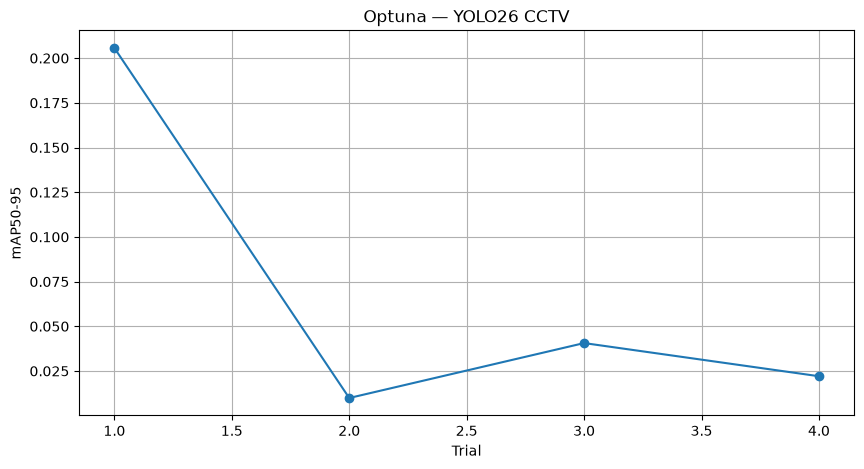

In [9]:
completed = [
    t
    for t in study.trials
    if t.state
    == optuna.trial.TrialState.COMPLETE
]


if completed:

    best_trial = study.best_trial

    print("=" * 70)
    print("BEST TRIAL")
    print("=" * 70)

    print(
        "Trial:",
        best_trial.number
    )

    print(
        "mAP50-95:",
        best_trial.value
    )

    print()
    print("Hyperparameters:")

    for key, value in best_trial.params.items():

        print(
            f"{key}: {value}"
        )


    # --------------------------------------------------------
    # График
    # --------------------------------------------------------

    plot_df = pd.DataFrame([
        {
            "trial": t.number,
            "mAP50-95": t.value
        }
        for t in completed
    ])


    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        plot_df["trial"],
        plot_df["mAP50-95"],
        marker="o"
    )

    plt.xlabel("Trial")
    plt.ylabel("mAP50-95")
    plt.title("Optuna — YOLO26 CCTV")

    plt.grid(True)

    plt.show()

else:

    print(
        "Пока нет завершённых trial."
    )

# Лучшие параметры

In [10]:
if not completed:

    raise RuntimeError(
        "Нет завершённых trial."
    )


best_params = study.best_trial.params

print("Best parameters:")

for key, value in best_params.items():

    print(
        f"{key}: {value}"
    )

Best parameters:
optimizer: AdamW
lr0: 0.0003287747413991121
lrf: 0.048164145309070844
weight_decay: 1.4648955132800731e-05
imgsz: 768
scale: 0.03487346516301046
translate: 0.04382169728028272
fliplr: 0.18318092164684585
hsv_h: 0.009121399684340718
hsv_s: 0.3925879806965068
hsv_v: 0.09983689107917987
mosaic: 0.2571172192068058


# Финальное обучение на лучших параметрах

In [11]:
best_model = YOLO(
    MODEL_WEIGHTS
)

best_model.train(

    data=str(DATA_YAML),

    epochs=MAX_EPOCHS,

    device=DEVICE,

    project=str(RUNS_DIR),

    name="final_best",

    exist_ok=True,

    workers=4,

    batch=8,

    save=True,

    save_period=1,

    seed=42,

    **best_params
)

New https://pypi.org/project/ultralytics/8.4.150 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.142  Python-3.12.3 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3070 Laptop GPU, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\\Desktop\\data_preproc\test_pipeline\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.18318092164684585, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.009121399684340718, hsv_s=0.3925879806965068, hsv_v=0.09983689107917987, imgsz=768, iou=0.7, keras=False, ko

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000026A8064D490>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
       